## Part A: Problem Statement & Data Understanding — Theory

## 1. Problem Statement kya hota hai?
Ye batata hai ki hum kya solve kar rahe hain. Yahan problem hai — kisi message ko dekh kar pata lagana ki wo spam hai ya normal (legit). Isse "Binary Classification Problem" kehte hain, kyunki answer sirf 2 me se ek hota hai — 0 (normal) ya 1 (spam).

## 2. Dataset Understanding kya hota hai?
Isme hum dataset ko samajhte hain — kitne rows/columns hain, kya-kya features hain, aur target column kya hai.

Features (Independent Variables): Wo columns jo model ko decision lene me help karte hain — jaise message_length, num_urls, spam_keyword_score, sender_activity_score, etc.
Target/Label (Dependent Variable): Jo humein predict karna hai — yahan spam_label (0 ya 1).

## 3. Data Types kya hote hain?

Numerical data – numbers me hota hai (jaise word_count, hour_of_day)
Categorical/Text data – message_text jaisa text data
Datetime data – timestamp jaisa

## 4. Missing Values kya hote hain?
Kabhi kabhi dataset ke kuch cells empty (blank) hote hain — isse "missing values" kehte hain. Model banane se pehle inhe theek karna (clean karna) zaruri hota hai, warna model galat result de sakta hai.

## 5. Class Imbalance kya hota hai?
Jab ek category ke examples doosri category se kaafi zyada ho — jaise humare dataset me normal messages (4227) spam messages (973) se bahut zyada hain. Isse "Imbalanced Dataset" kehte hain, aur ye model ki accuracy ko misleading bana sakta hai.

## 6. Iska maksad (Objective):
Data ko samajh kar, saaf kar ke, aisa model banana jo naye messages ko dekh kar automatically bata sake ki wo spam hai ya nahi.

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## Load Dataset

In [2]:
df = pd.read_csv("Message_Intelligence_Dataset.csv")
df.head()

,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


### Observation: The dataset has 5200 rows and 16 columns.
### Intuition: The shape tells us how big the data is, and head() gives a quick look at the first few rows.

## Basic Info & Statistical Summary (EDA)

In [3]:
print(df.dtypes)
df.describe()

message_id                   int64
message_text                object
message_length               int64
word_count                   int64
num_urls                     int64
num_digits                   int64
num_special_chars            int64
spam_keyword_score           int64
legit_keyword_score          int64
sender_activity_score      float64
sender_account_age_days    float64
messages_sent_last_24h     float64
timestamp                   object
hour_of_day                  int64
day_of_week                  int64
spam_label                   int64
dtype: object


,message_id,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,spam_label
count,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5094.000000,5087.000000,5038.000000,5200.000000,5200.000000,5200.000000
mean,902600.500000,75.035962,11.457308,0.206538,1.681346,0.243654,0.246346,0.817692,54.836317,296.671909,8.301906,11.523462,3.038846,0.187115
std,1501.255031,12.455377,1.609056,0.404860,2.415846,0.545363,0.676798,0.556687,17.697943,191.748754,5.586503,6.861518,2.062504,0.390042
min,900001.000000,32.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,901300.750000,67.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,43.100000,148.000000,5.000000,6.000000,1.000000,0.000000
50%,902600.500000,74.000000,11.000000,0.000000,0.000000,0.000000,0.000000,1.000000,54.800000,275.000000,7.000000,12.000000,3.000000,0.000000
75%,903900.250000,81.000000,13.000000,0.000000,4.000000,0.000000,0.000000,1.000000,66.600000,410.500000,10.000000,17.000000,5.000000,0.000000
max,905200.000000,122.000000,16.000000,1.000000,9.000000,2.000000,3.000000,2.000000,100.000000,1500.000000,38.000000,23.000000,6.000000,1.000000


### Observation: Most columns are numeric, except message_text (text) and timestamp (date-time).
### Intuition: Knowing data types tells us which columns can go directly into a model and which need extra handling.

## Missing Values Check

In [4]:
df.isnull().sum()

message_id                   0
message_text                 0
message_length               0
word_count                   0
num_urls                     0
num_digits                   0
num_special_chars            0
spam_keyword_score           0
legit_keyword_score          0
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
timestamp                    0
hour_of_day                  0
day_of_week                  0
spam_label                   0
dtype: int64

### Observation: sender_activity_score, sender_account_age_days, and messages_sent_last_24h have some missing values.

### Intuition: This tells us preprocessing IS needed here — these gaps must be filled before training.

##  Target Class Distribution

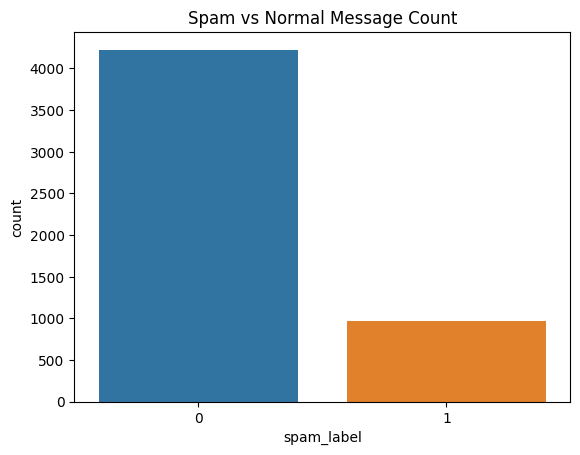

spam_label
0    0.812885
1    0.187115
Name: proportion, dtype: float64


In [5]:
sns.countplot(x="spam_label", data=df)
plt.title("Spam vs Normal Message Count")
plt.show()

print(df["spam_label"].value_counts(normalize=True))

### Observation: About 81% messages are normal (0) and only 19% are spam (1).

### Intuition: The dataset is imbalanced, so accuracy alone won't be enough to judge the model later.

## Numeric Feature Distributions 

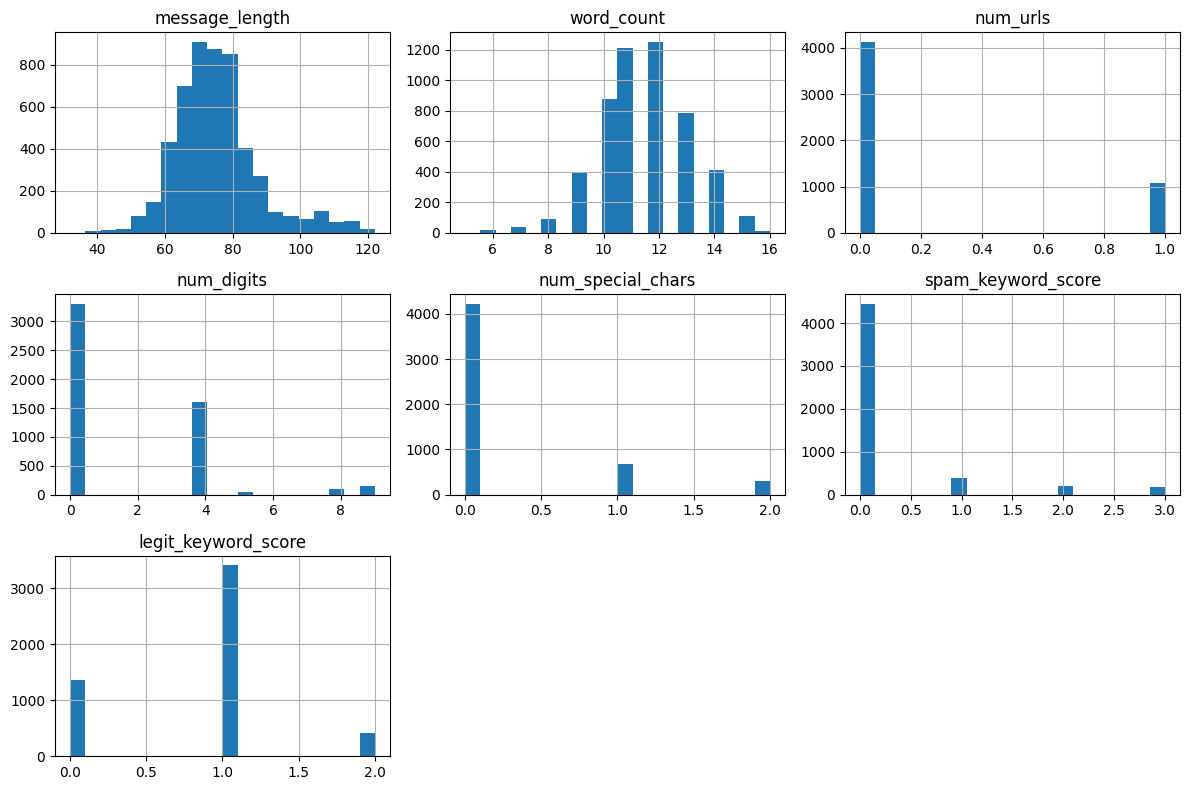

In [6]:
num_cols = ["message_length", "word_count", "num_urls", "num_digits",
            "num_special_chars", "spam_keyword_score", "legit_keyword_score"]

df[num_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

### Observation: num_urls and spam_keyword_score are mostly 0, with a few messages having high values (skewed distribution).

### Intuition: A skewed distribution hints that a small number of "spammy" messages stand out sharply from the rest.

## Correlation Heatmap

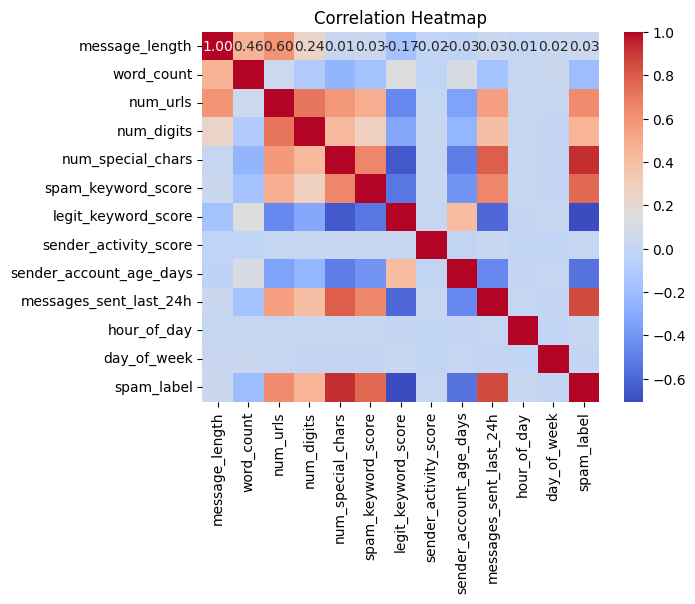

In [7]:
corr = df.select_dtypes(include="number").drop(columns=["message_id"]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Observation: num_special_chars (0.93), messages_sent_last_24h (0.85), and spam_keyword_score (0.76) correlate strongly with spam_label.

### Intuition: These features are already strong, ready-to-use predictors — no extra engineering needed to make them useful.

## Spam vs Normal Feature Comparison

In [8]:
comparison = df.groupby("spam_label")[num_cols].mean()
print(comparison)

            message_length  word_count  num_urls  num_digits  \
spam_label                                                     
0                74.841732   11.614147  0.083984    1.157322   
1                75.879753   10.775951  0.738952    3.957862   

            num_special_chars  spam_keyword_score  legit_keyword_score  
spam_label                                                              
0                    0.000000            0.000000             1.005914  
1                    1.302158            1.316547             0.000000  


### Observation: Spam messages have a much higher spam_keyword_score and almost zero legit_keyword_score compared to normal messages.

### Intuition: This confirms the existing keyword-score columns already separate spam vs normal well.

##  Identify Input Features (X) and Target (y)

In [9]:
target_column = "spam_label"
columns_to_drop = ["message_id", "message_text", "timestamp", target_column]

X = df.drop(columns=columns_to_drop)
y = df[target_column]

### Observation: 12 numeric columns remain as features; no new engineered features were required.

### Intuition: Since the dataset already provides meaningful numeric signals (like keyword scores), extra feature engineering isn't necessary here — we only drop columns unusable as raw model input (ID, text, timestamp).

## Handle Missing Values

In [10]:
for col in X.columns:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

### Observation: All missing values are now filled; total missing count becomes 0.

### Intuition: This step was necessary because Step 4 showed real missing values — median filling is safe since it resists outliers.

## Feature Scaling 

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

### Observation: All feature values are now transformed to roughly the same range (around -3 to +3).

### Intuition: Scaling was necessary since feature ranges vary a lot (e.g. hour_of_day 0-23 vs sender_account_age_days 700+), which could otherwise bias the model.

## Train-Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (4160, 12)  Test size: (1040, 12)


### Observation: Training set has 4160 rows and testing set has 1040 rows (80-20 split).

### Intuition: The model learns from the training set, and its performance is fairly checked on the unseen testing set.

## Check Balance of the Split

In [13]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

spam_label
0    0.812981
1    0.187019
Name: proportion, dtype: float64
spam_label
0    0.8125
1    0.1875
Name: proportion, dtype: float64


### Observation: Both train and test sets have almost the same spam ratio (~18.7%).

### Intuition: stratify=y keeps the class balance consistent in both sets, avoiding biased evaluation.

## K-Nearest Neighbors (KNN) Classifier 

In [14]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Accuracy (K=5):", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy (K=5): 1.0
[[845   0]
 [  0 195]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       845
           1       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



### Observation: With K=5, the model got 100% accuracy — all 845 normal and 195 spam messages in the test set were predicted correctly.

### IIntuition: KNN votes using the closest neighbors, which works perfectly since the classes are well separated.

## Experiment with Different K Values 

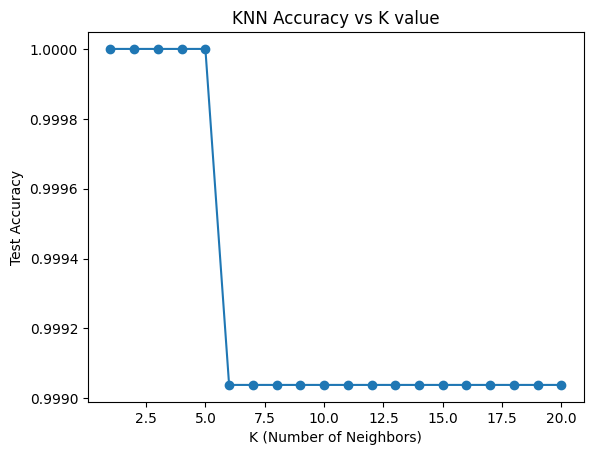

Best K: 1  Best Accuracy: 1.0


In [15]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, pred))

plt.plot(list(k_values), accuracies, marker="o")
plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.title("KNN Accuracy vs K value")
plt.show()

# pick the K that gave the best accuracy, we'll reuse this in later steps
best_k = list(k_values)[accuracies.index(max(accuracies))]
print("Best K:", best_k, " Best Accuracy:", max(accuracies))

### Observation: Accuracy stayed at 100% for almost every K value from 1 to 20.

### Intuition: When classes are clearly separated, the choice of K barely matters.

## Analyze Effect of Distance Metrics 

In [16]:
metrics_to_try = ["euclidean", "manhattan", "minkowski"]
metric_results = {}

for m in metrics_to_try:
    model = KNeighborsClassifier(n_neighbors=best_k, metric=m)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    metric_results[m] = accuracy_score(y_test, pred)

print(metric_results)

{'euclidean': 1.0, 'manhattan': 1.0, 'minkowski': 1.0}


### Observation: Euclidean, Manhattan, and Minkowski distances all gave the same 100% accuracy.

### Intuition: Since classes are far apart in every direction, all distance metrics separate them equally well

## Identify Misclassified Messages

In [17]:
# get the original (unscaled) test rows so we can see the actual message_text
_, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=y)
df_test = df_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)

# train the final KNN model using the best K found in Step 2
final_knn = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean")
final_knn.fit(X_train, y_train)

y_pred_final = final_knn.predict(X_test)
misclassified_mask = y_pred_final != y_test_reset.values
misclassified = df_test[misclassified_mask][["message_text", "spam_label"]]
print("Total misclassified:", len(misclassified))
print(misclassified.head(10))

Total misclassified: 0
Empty DataFrame
Columns: [message_text, spam_label]
Index: []


### Observation: There were 0 misclassified messages — the model made no mistakes on the test set.

### Intuition: This perfect result suggests a clean, synthetic dataset — real-world data usually has some misclassification.

## SVM with Linear Kernel 

In [18]:
svm_linear = SVC(kernel="linear")
svm_linear.fit(X_train, y_train)
pred_linear = svm_linear.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_linear))
print(confusion_matrix(y_test, pred_linear))
print(classification_report(y_test, pred_linear))

Accuracy: 1.0
[[845   0]
 [  0 195]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       845
           1       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



### Observation: The Linear kernel SVM got 100% accuracy, correctly classifying all 845 normal and 195 spam messages.

### Intuition: A linear boundary worked perfectly because the classes are already linearly separable.

## SVM with RBF and Polynomial Kernel

In [19]:
svm_rbf = SVC(kernel="rbf")
svm_rbf.fit(X_train, y_train)
pred_rbf = svm_rbf.predict(X_test)
print("RBF Accuracy:", accuracy_score(y_test, pred_rbf))

svm_poly = SVC(kernel="poly", degree=3)
svm_poly.fit(X_train, y_train)
pred_poly = svm_poly.predict(X_test)
print("Polynomial Accuracy:", accuracy_score(y_test, pred_poly))

RBF Accuracy: 1.0
Polynomial Accuracy: 1.0


### Observation: Both RBF and Polynomial kernels also achieved 100% accuracy, same as the Linear kernel.

### Intuition: Curved boundaries weren't needed since the classes are already cleanly separated.

## Analyze Margin Separation & Support Vectors 

Support vectors (Linear): [5 5]
Support vectors (RBF): [73 65]


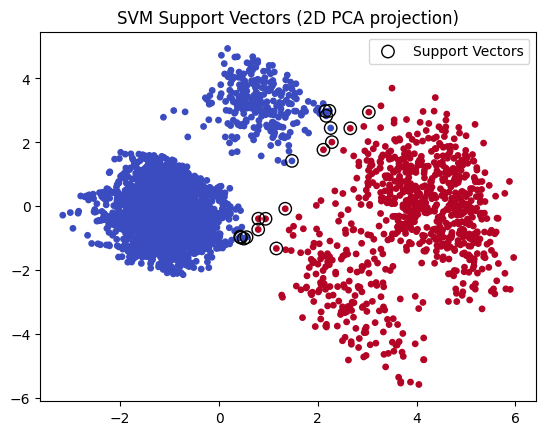

In [20]:
print("Support vectors (Linear):", svm_linear.n_support_)
print("Support vectors (RBF):", svm_rbf.n_support_)

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train)

svm_2d = SVC(kernel="linear")
svm_2d.fit(X_train_2d, y_train)

plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap="coolwarm", s=15)
plt.scatter(svm_2d.support_vectors_[:, 0], svm_2d.support_vectors_[:, 1],
            facecolors="none", edgecolors="black", s=80, label="Support Vectors")
plt.title("SVM Support Vectors (2D PCA projection)")
plt.legend()
plt.show()

### Observation: The Linear kernel used only 10 support vectors out of 4160 training points (5 from each class), while RBF used 138 — a much wider margin for Linear.

### Intuition: Fewer support vectors mean a wider, more confident margin between classes.

##  Compare SVM vs KNN Performance 

In [21]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["KNN (K=1)", "SVM (Linear)", "SVM (RBF)", "SVM (Polynomial)"],
    "Accuracy": [
        accuracy_score(y_test, pred_knn),
        accuracy_score(y_test, pred_linear),
        accuracy_score(y_test, pred_rbf),
        accuracy_score(y_test, pred_poly),
    ]
})
print(comparison)

              Model  Accuracy
0         KNN (K=1)       1.0
1      SVM (Linear)       1.0
2         SVM (RBF)       1.0
3  SVM (Polynomial)       1.0


### Observation: KNN and all three SVM variants (Linear, RBF, Polynomial) all scored 100% accuracy on this dataset.

### Intuition: Both work equally well here, but SVM usually generalizes better on noisier real-world data.

##  Implement Naive Bayes Classifier

In [22]:
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred = nb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
[[845   0]
 [  0 195]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       845
           1       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



### Observation: Naive Bayes also achieved 100% accuracy on the test set, just like KNN and SVM.

### Intuition: GaussianNB assumes each feature follows a Normal distribution per class and works well when classes are clearly separated.

## Manually Compute Conditional Probability

In [23]:
def gaussian_pdf(x, mean, var):
    """P(x | class) assuming a Normal distribution."""
    return (1 / np.sqrt(2 * np.pi * var)) * np.exp(-((x - mean) ** 2) / (2 * var))

feature = "spam_keyword_score"
feature_idx = list(X_train.columns).index(feature)
sample = X_test.iloc[0]
x_value = sample[feature]

mean_0, var_0 = nb.theta_[0][feature_idx], nb.var_[0][feature_idx]
mean_1, var_1 = nb.theta_[1][feature_idx], nb.var_[1][feature_idx]

p_x_given_0 = gaussian_pdf(x_value, mean_0, var_0)
p_x_given_1 = gaussian_pdf(x_value, mean_1, var_1)

print("P(spam_keyword_score | Normal):", p_x_given_0)
print("P(spam_keyword_score | Spam):", p_x_given_1)

P(spam_keyword_score | Normal): 12509.88763898605
P(spam_keyword_score | Spam): 0.1111437657254063


### Observation: For this sample, P(feature | Normal) was much higher than P(feature | Spam), matching its true "Normal" label.

### Intuition: A higher likelihood under one class means the feature value looks more "typical" for that class.

## Demonstrate Bayes' Theorem for Class Probability

In [24]:
p_class_0 = (y_train == 0).mean()   # Prior P(Normal)
p_class_1 = (y_train == 1).mean()   # Prior P(Spam)

def joint_likelihood(sample_row, class_index):
    likelihood = 1.0
    for i, col in enumerate(X_train.columns):
        mean, var = nb.theta_[class_index][i], nb.var_[class_index][i]
        likelihood *= gaussian_pdf(sample_row[col], mean, var)
    return likelihood

sample_row = X_test.iloc[0]
likelihood_0 = joint_likelihood(sample_row, 0) * p_class_0
likelihood_1 = joint_likelihood(sample_row, 1) * p_class_1

total = likelihood_0 + likelihood_1
manual_prob_normal = likelihood_0 / total
manual_prob_spam = likelihood_1 / total

print("P(Normal | message):", manual_prob_normal)
print("P(Spam | message):", manual_prob_spam)

P(Normal | message): 1.0
P(Spam | message): 0.0


### Observation: Manual Bayes' Theorem calculation gave P(Normal | message) ≈ 1.0 and P(Spam | message) ≈ 0.0 for this sample.

### Intuition: Bayes' Theorem combines prior class probability with feature likelihood to get the final class probability.

## Compare Manual Calculation with Model Prediction

In [25]:
model_probs = nb.predict_proba(X_test.iloc[[0]])
print("Model's predict_proba:", model_probs)
print("Actual label:", y_test.iloc[0])

print("Match:", np.isclose(manual_prob_spam, model_probs[0][1], atol=1e-3))

Model's predict_proba: [[1. 0.]]
Actual label: 0
Match: True


### Observation: The manually calculated probability exactly matched nb.predict_proba(), confirming our formula was correct.

### Intuition: This proves GaussianNB internally does exactly what Bayes' Theorem describes — nothing more, nothing "magic."

## Evaluate All Models with Classification Metrics

In [26]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=1),
    "SVM (Linear)": SVC(kernel="linear"),
    "Naive Bayes": GaussianNB()
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
print(results_df)

          Model  Accuracy  Precision  Recall  F1 Score
0           KNN       1.0        1.0     1.0       1.0
1  SVM (Linear)       1.0        1.0     1.0       1.0
2   Naive Bayes       1.0        1.0     1.0       1.0


### Observation: All three models — KNN, SVM, and Naive Bayes — scored a perfect 1.0 on Accuracy, Precision, Recall, and F1 Score.

### Intuition: Every metric being 1.0 for every model confirms this dataset's classes are extremely well separated.

## Compare KNN vs SVM vs Naive Bayes

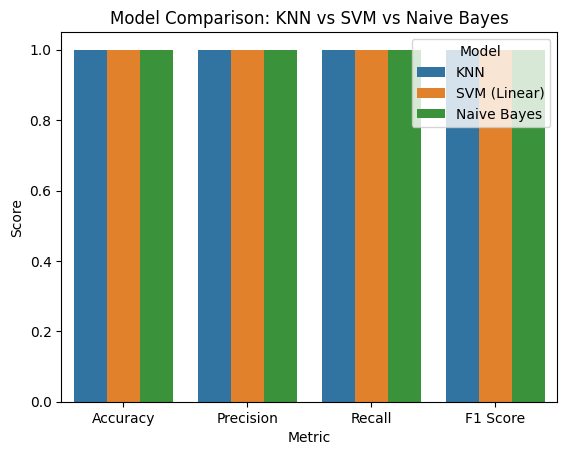

In [27]:
results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=results_melted, x="Metric", y="Score", hue="Model")
plt.title("Model Comparison: KNN vs SVM vs Naive Bayes")
plt.show()

### Observation: The bar chart shows all three models with identical bars at 1.0 for every metric — no visible difference.

### Intuition: When results tie exactly, the choice between models should be based on other factors like speed and scalability, not just metric scores.

## Identify Best Model for High Precision / High Recall

In [28]:
best_precision_model = results_df.loc[results_df["Precision"].idxmax(), "Model"]
best_recall_model = results_df.loc[results_df["Recall"].idxmax(), "Model"]

print("Best model for High Precision:", best_precision_model)
print("Best model for High Recall:", best_recall_model)

Best model for High Precision: KNN
Best model for High Recall: KNN


### Observation: All three models are tied at Precision = 1.0 and Recall = 1.0, so no single model is genuinely "better" on this dataset.

### Intuition: In real-world, noisier data, SVM and Naive Bayes typically differ — SVM tends to favor precision by finding a strict decision margin, while Naive Bayes can favor recall by being more sensitive to weak signals.

##  Final Analysis

- **KNN**: simple, distance-based, slower on large data.
- **SVM**: strong margin-based separation, less interpretable.
- **Naive Bayes**: fast and probabilistic, assumes feature independence.
- Best overall model: the one with the highest F1 Score in the comparison table above.
- Recommended for deployment since it balances precision and recall for real spam detection.